# Portfolio Assessment 2
## Advanced Data Preprocessing, Feature Engineering & Model Development
**COS40007 - Artificial Intelligence Engineering**  
**Nguyen Van Tuan Kiet | Student ID: 104772099**  
**Class identifier: COS40007 | Prepared: 16 October 2026**  
**GitHub Repository:** [https://github.com/odmiefnf/COS40007](https://github.com/odmiefnf/COS40007)  
**PA2 code and files:** [portfolio/assessment-2](https://github.com/odmiefnf/COS40007/tree/main/portfolio/assessment-2)

### Replacement dataset: Building Energy Efficiency
This version replaces the concrete dataset after checking the Studio 2/3 restriction.
The new EDA is included here and is not claimed to have been part of the submitted
Portfolio 1. It provides the evidence needed to connect preprocessing with modelling.

### Generative AI use declaration
OpenAI Codex assisted with experimental design, code implementation, debugging, feature
ideas, execution, analysis, interpretation and report drafting. The assistant executed
code and checked the outputs; student review and verification remain pending. This
document does not claim independent student authorship or completed student verification.
The actual assistance exceeds the examples listed in the brief; its acceptability must
be confirmed before submission. GENAI_EVIDENCE.md records the assistance honestly.

### Acknowledgement of Country
I acknowledge the Traditional Owners of the lands on which Swinburne operates and pay
respect to Elders past and present. I recognise the continuing connections of Aboriginal
and Torres Strait Islander peoples to Country, culture and community.

### Aim
Classify simulated residential-building heating load into three relative demand bands
using geometry, orientation and glazing inputs. These are educational classes, not
official energy-efficiency ratings, and the model is not a building compliance assessment.

## Scope, sources and evaluation plan
The Portfolio Task 2 brief, Canvas rubric and Studio 3 define Tasks 1-10 below. Exactly
five Decision Tree configurations reconcile the brief's "at least five" and rubric's
"at most five" wording. Controlled raw/scaled/engineered/selected comparisons follow
Studio 3; its illustrative four fixed features are adapted to a selected feature set.

The user chose a new dataset after the concrete data in Portfolio 1 was verified to match
the prohibited Studio 2 sample. The replacement is UCI Energy Efficiency [1]. Sections
EDA A-C below supply fresh evidence; they do not invent an earlier Energy Portfolio 1.

Split the 768 observations randomly 70/30 with seed 42 before fitting class thresholds or
examining training distributions. Training-only heating-load terciles define three bands;
the same cutoffs label validation and holdout observations. Training folds are stratified
after this label definition. A 5-fold training CV selects tree representation; nested
5-fold CV evaluates SVM tuning/selection/PCA procedures. All transformations are fit in
the appropriate training folds. Test scores are reported only after configurations are
locked; selection does not use the test. A grouped sensitivity check holds out complete
building geometries. One dataset and one split do not establish external generalisation.

The supplied PDF has the old date 01/04/2026. Canvas displayed 18 October 2026 23:59 as
the deadline and 22 October as availability end; availability is not an extension.
The source notebook, dataset and supporting files accompany this report at the GitHub link on the cover. Canvas submission has not been performed.

CV estimates are conditional on the demand-band definition fixed from the full training partition. They do not evaluate a new discretisation rule in each outer fold. The holdout never contributes to the cutoffs.

In [1]:
from pathlib import Path
import hashlib, json, platform, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import (train_test_split, StratifiedKFold,
    StratifiedGroupKFold, GridSearchCV, cross_val_score, cross_validate)
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report)
from sklearn.inspection import permutation_importance
import sklearn, scipy, matplotlib

ROOT = Path.cwd()
if not (ROOT / 'data/energy_data.csv').exists():
    ROOT = ROOT / 'portfolio2_energy'
assert (ROOT / 'data/energy_data.csv').exists(), 'Open notebook from portfolio2 folder'
OUT = ROOT / 'output'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
SEED = 42
plt.rcParams.update({'figure.dpi': 125, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 130)
def table(frame, filename=None):
    if filename:
        frame.to_csv(OUT / filename, index=True)
    print(frame.to_string(float_format=lambda x: f'{x:.4f}'))
def figure(name):
    plt.tight_layout()
    plt.savefig(FIG / f'{name}.png', dpi=180, bbox_inches='tight')
    plt.show()
    plt.close('all')
def note(s): display(Markdown(s))
versions = {'python': platform.python_version(), 'numpy': np.__version__,
    'pandas': pd.__version__, 'scikit-learn': sklearn.__version__,
    'scipy': scipy.__version__, 'matplotlib': matplotlib.__version__}
print(json.dumps(versions, indent=2))

{
  "python": "3.12.14",
  "numpy": "2.3.5",
  "pandas": "3.0.1",
  "scikit-learn": "1.9.1",
  "scipy": "1.18.1",
  "matplotlib": "3.11.2"
}


## Task 1 and EDA A - Data quality and target preparation
UCI Energy Efficiency has 768 simulated cases, eight inputs and two numerical responses.
It varies 12 underlying building shapes, orientation and glazing settings [1]. Select
Y1 (heating load) as the target. **Y2 (cooling load) is excluded entirely from predictors**:
it is a related simulation outcome, not a design input available for the prediction task.
The original workbook is preserved; energy_data.csv is a lossless numerical export.

Use the first eight columns only. Geometry and glazing amount are numerical. Orientation
(codes 2-5) and glazing distribution (codes 0-5) are nominal despite numerical storage.
Drop fully empty rows/columns if present, check missingness and duplicates, and retain
valid extremes. No data are removed when the checks find no defects.

A random 70/30 split is made before fitting the two heating-load terciles on the training
partition. The label order is Lower=0, Middle=1, Higher=2, with right-closed intervals.
The cuts are training-relative demand bands, not physical code thresholds. Validation and
test use those fixed cuts without refitting. Approximate balance is checked for all
partitions below. Discretisation loses load detail and introduces boundary sensitivity.
Loads are reported in dataset units because the UCI variable table does not specify units.

        All  Train  Test  All_percent
Lower   246    179    67      32.0312
Middle  255    179    76      33.2031
Higher  267    179    88      34.7656
Source workbook SHA256: 0089fcffc1415e41e2ff63730cca5280efe54fc43d722dfde1b0aaa808e35dc4
CSV SHA256: 483904d33ab6db8bb0d1791d81410c18567c6b967035325a844de8ca97046ddc
Rows raw/retained: 768 768 duplicates: 0
Train/test rows: 537 231
Training-only band cutoffs: [14.463333333333333, 28.406666666666666]


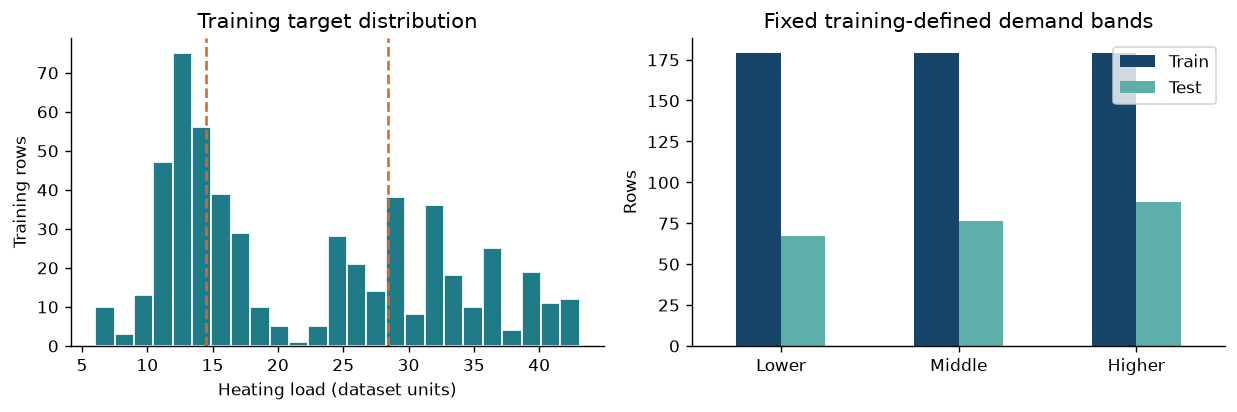

In [2]:
source = ROOT / 'data/energy_data.csv'
source_hash = hashlib.sha256(source.read_bytes()).hexdigest()
assert source_hash == '483904d33ab6db8bb0d1791d81410c18567c6b967035325a844de8ca97046ddc'
workbook_hash = hashlib.sha256((ROOT/'data/ENB2012_data.xlsx').read_bytes()).hexdigest()
raw = pd.read_csv(source)
data = raw.dropna(how='all').dropna(axis=1,how='all').drop_duplicates().reset_index(drop=True)
assert data.shape == (768,10) and not data.isna().any().any()
data.columns = ['relative_compactness','surface_area','wall_area','roof_area',
    'overall_height','orientation','glazing_area','glazing_distribution',
    'heating_load','cooling_load']
ORIGINAL = list(data.columns[:8])
NUMERIC = ['relative_compactness','surface_area','wall_area','roof_area',
    'overall_height','glazing_area']
CATEGORICAL = ['orientation','glazing_distribution']
TARGET = 'heating_load'
assert (data[NUMERIC] >= 0).all().all()
assert set(data.orientation.unique()) == {2,3,4,5}
assert set(data.glazing_distribution.unique()) == set(range(6))
train_idx,test_idx=train_test_split(np.arange(len(data)),test_size=.30,
    random_state=SEED,shuffle=True)
cutoffs=data[TARGET].iloc[train_idx].quantile([1/3,2/3]).to_list()
EDGES=[-np.inf,*cutoffs,np.inf]
LABELS=['Lower','Middle','Higher']
y=pd.cut(data[TARGET],EDGES,labels=False,right=True).astype(int)
X=data[ORIGINAL].copy()
Xtr,Xte=X.iloc[train_idx].copy(),X.iloc[test_idx].copy()
ytr,yte=y.iloc[train_idx].copy(),y.iloc[test_idx].copy()
load_tr=data[TARGET].iloc[train_idx]
assert not set(train_idx)&set(test_idx)
assert 'heating_load' not in X and 'cooling_load' not in X
class_table=pd.DataFrame({'All':y.value_counts().sort_index(),
    'Train':ytr.value_counts().sort_index(),'Test':yte.value_counts().sort_index()})
class_table.index=LABELS
class_table['All_percent']=class_table.All/len(data)*100
table(class_table,'class_distribution.csv')
print('Source workbook SHA256:',workbook_hash)
print('CSV SHA256:',source_hash)
print('Rows raw/retained:',len(raw),len(data),'duplicates:',raw.duplicated().sum())
print('Train/test rows:',len(Xtr),len(Xte))
print('Training-only band cutoffs:',cutoffs)
shuffled=data.assign(source_row_id=np.arange(len(data)),demand_band=y).sample(
    frac=1,random_state=SEED).reset_index(drop=True)
shuffled.to_csv(OUT/'shuffled_energy.csv',index=False)
split=pd.DataFrame({'source_row_id':np.arange(len(data)),'partition':'train'})
split.loc[test_idx,'partition']='test'
split.to_csv(OUT/'split_manifest.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(10,3.4))
axes[0].hist(load_tr,bins=25,color='#207b88',edgecolor='white')
for b in cutoffs: axes[0].axvline(b,color='#cb6c35',linestyle='--')
axes[0].set(xlabel='Heating load (dataset units)',ylabel='Training rows',title='Training target distribution')
class_table[['Train','Test']].plot.bar(ax=axes[1],rot=0,color=['#174469','#5eafaa'])
axes[1].set(ylabel='Rows',title='Fixed training-defined demand bands')
figure('01_target')

## Task 2 and EDA B - Distributions, normalisation and encoding
The following training summary documents numerical skew, Tukey-IQR flags and selected
scaling for each input. With any IQR flags use RobustScaler; with |skew|>1 and no flags
use MinMaxScaler; otherwise use StandardScaler. This distribution rule does not assert
Gaussianity. Binary one-hot indicators remain 0/1. Scaling changes units, not skew or
outlier membership; valid extremes remain in the data [2]. No imputation is required.

Orientation and glazing-distribution codes are nominal. Encode their documented finite
vocabularies with one-hot indicators rather than imposing an artificial numeric distance.
All six geometry/glazing measurements are scaled; the ten resulting category indicators
are preserved. A fixed vocabulary does not learn from the test. Unknown category codes
raise an error. EDA plots show each original numerical input before and after scaling,
and category frequencies. Trees are expected to be insensitive to monotone scaling;
SVM kernels and PCA depend on the resulting feature scales.

                        Train_skew  IQR_flags          Scaler                          Reason  Raw_min  Raw_max  Scaled_min  Scaled_max
relative_compactness        0.5325          0  StandardScaler  Moderate skew, no IQR outliers   0.6200   0.9800     -1.3406      2.0980
surface_area               -0.1572          0  StandardScaler  Moderate skew, no IQR outliers 514.5000 808.5000     -1.8291      1.5242
wall_area                   0.5331          0  StandardScaler  Moderate skew, no IQR outliers 245.0000 416.5000     -1.6897      2.2457
roof_area                  -0.2179          0  StandardScaler  Moderate skew, no IQR outliers 110.2500 220.5000     -1.5149      0.9461
overall_height              0.0560          0  StandardScaler  Moderate skew, no IQR outliers   3.5000   7.0000     -0.9724      1.0283
glazing_area               -0.0867          0  StandardScaler  Moderate skew, no IQR outliers   0.0000   0.4000     -1.7608      1.2244
orientation_2               1.2195        129  S

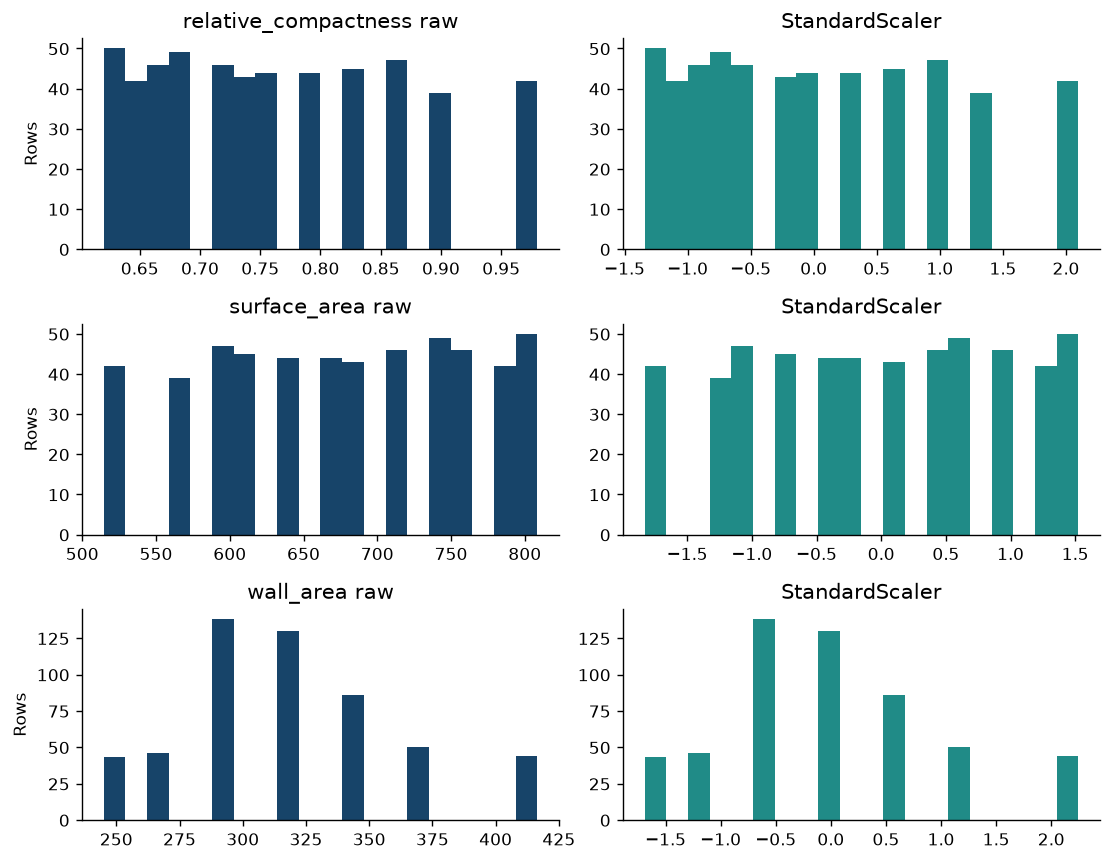

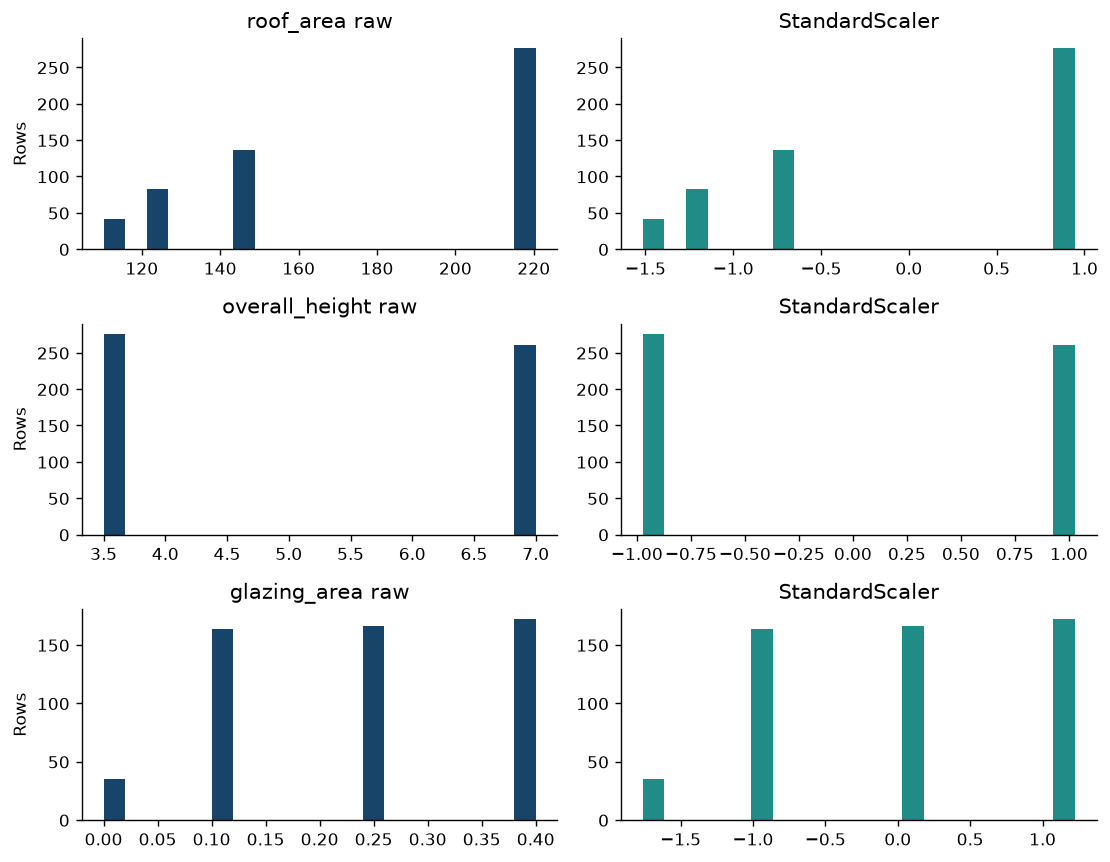

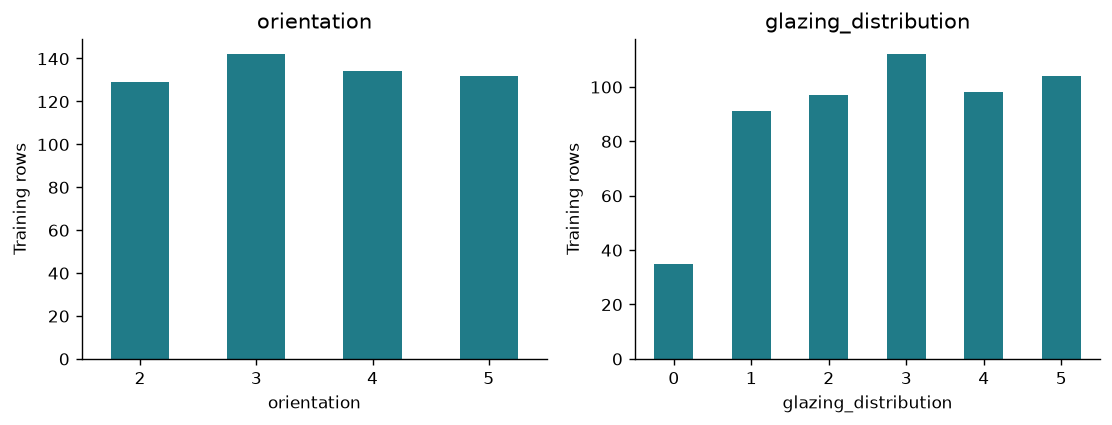

In [3]:
class BuildingEncoding(TransformerMixin,BaseEstimator):
    def __init__(self,engineer=False): self.engineer=engineer
    def fit(self,X,y=None):
        self.n_features_in_=X.shape[1]
        return self
    def transform(self,X):
        z=X[NUMERIC].copy()
        if self.engineer:
            if not (z.surface_area>0).all(): raise ValueError('Nonpositive surface area')
            z['wall_to_surface']=z.wall_area/z.surface_area
            z['roof_to_surface']=z.roof_area/z.surface_area
            z['glazing_wall_interaction']=z.glazing_area*z.wall_area
            z['glazing_height_interaction']=z.glazing_area*z.overall_height
            z['compactness_glazing']=z.relative_compactness*z.glazing_area
        for name,levels in [('orientation',range(2,6)),('glazing_distribution',range(6))]:
            if not X[name].isin(levels).all(): raise ValueError('Unknown category')
            for k in levels: z[f'{name}_{k}']=(X[name]==k).astype(float)
        return z

class DistributionScaler(TransformerMixin,BaseEstimator):
    def fit(self,X,y=None):
        a=np.asarray(X,dtype=float)
        self.n_features_in_=a.shape[1]
        self.scalers_,self.audit_=[],[]
        for j in range(a.shape[1]):
            s=pd.Series(a[:,j]); q1,q3=s.quantile([.25,.75]); iqr=q3-q1
            flags=(s<q1-1.5*iqr)|(s>q3+1.5*iqr)
            if set(s.unique()).issubset({0.,1.}):
                sc,reason=StandardScaler(with_mean=False,with_std=False),'Binary indicator retained'
            elif flags.any(): sc,reason=RobustScaler(),'IQR outliers'
            elif abs(s.skew())>1: sc,reason=MinMaxScaler(),'Skew without IQR outliers'
            else: sc,reason=StandardScaler(),'Moderate skew, no IQR outliers'
            self.scalers_.append(sc.fit(a[:,[j]]))
            self.audit_.append((float(s.skew()),int(flags.sum()),type(sc).__name__,reason))
        return self
    def transform(self,X):
        a=np.asarray(X,dtype=float)
        return np.column_stack([sc.transform(a[:,[j]]).ravel() for j,sc in enumerate(self.scalers_)])

encoded_tr=BuildingEncoding().fit_transform(Xtr)
ENCODED_FEATURES=list(encoded_tr.columns)
scaler=DistributionScaler().fit(encoded_tr)
scaled_tr=scaler.transform(encoded_tr)
scaling_table=pd.DataFrame(scaler.audit_,index=ENCODED_FEATURES,
    columns=['Train_skew','IQR_flags','Scaler','Reason'])
scaling_table['Raw_min']=encoded_tr.min()
scaling_table['Raw_max']=encoded_tr.max()
scaling_table['Scaled_min']=scaled_tr.min(axis=0)
scaling_table['Scaled_max']=scaled_tr.max(axis=0)
table(scaling_table,'scaling_audit.csv')
table(Xtr[NUMERIC].describe().T,'training_eda_summary.csv')
for batch in range(2):
    fig,axes=plt.subplots(3,2,figsize=(9,7))
    for row,j in enumerate(range(batch*3,batch*3+3)):
        axes[row,0].hist(encoded_tr.iloc[:,j],bins=20,color='#174469')
        axes[row,0].set(title=f'{NUMERIC[j]} raw',ylabel='Rows')
        axes[row,1].hist(scaled_tr[:,j],bins=20,color='#208b87')
        axes[row,1].set(title=scaling_table.iloc[j].Scaler)
    figure(f'02_scaling_{batch+1}')
fig,axes=plt.subplots(1,2,figsize=(9,3.5))
for ax,n in zip(axes,CATEGORICAL):
    Xtr[n].value_counts().sort_index().plot.bar(ax=ax,color='#207b88',rot=0)
    ax.set(title=n,ylabel='Training rows')
figure('03_category_frequency')

## Task 3 and EDA C - Feature engineering and multicollinearity
Training EDA B shows repeated geometry levels and discrete glazing amounts. The target
correlations below test each proposed composition/interaction on training observations.
Create five features without either heating or cooling load:

- **wall_to_surface** = wall area/surface area. EDA B's geometry ranges motivate a wall
  exposure proportion that separates total envelope size from its composition.
- **roof_to_surface** = roof area/surface area. The complementary exposure hypothesis
  follows the strong geometric dependence examined in the heatmap below.
- **glazing_wall_interaction** = glazing amount x wall area. EDA B shows glazing varies
  in discrete steps across wall sizes; this is an exposure interaction proxy. Because
  the UCI variable table does not specify the reference area for glazing, it is not
  asserted to be literal window area in square metres.
- **glazing_height_interaction** = glazing amount x height. This tests whether glazing
  effects differ between the two observed height levels (EDA B).
- **compactness_glazing** = relative compactness x glazing amount. This represents a
  hypothesised interaction between building compactness and glazing exposure.

These are engineering hypotheses; the table and class boxplots validate association,
not causation. Correlated geometry and related ratios create redundancy. Report design
rank and the strongest predictor pair; PCA handles redundancy through a rotated
representation but cannot recover causal effects. No response enters model predictors.

                            Pearson_heating  Spearman_heating  Pearson_band  Minimum  Maximum
wall_to_surface                      0.8650            0.8548        0.8140   0.3571   0.6296
roof_to_surface                     -0.8650           -0.8548       -0.8140   0.1852   0.3214
glazing_wall_interaction             0.3850            0.4619        0.4023   0.0000 166.6000
glazing_height_interaction           0.6887            0.6519        0.6581   0.0000   2.8000
compactness_glazing                  0.4245            0.4975        0.4397   0.0000   0.3920
                      Pearson_heating  Spearman_heating
relative_compactness           0.6251            0.6236
surface_area                  -0.6607           -0.6236
wall_area                      0.4466            0.4590
roof_area                     -0.8637           -0.8113
overall_height                 0.8885            0.8605
glazing_area                   0.2810            0.3355
Strongest numerical predictor pair: ('wall_t

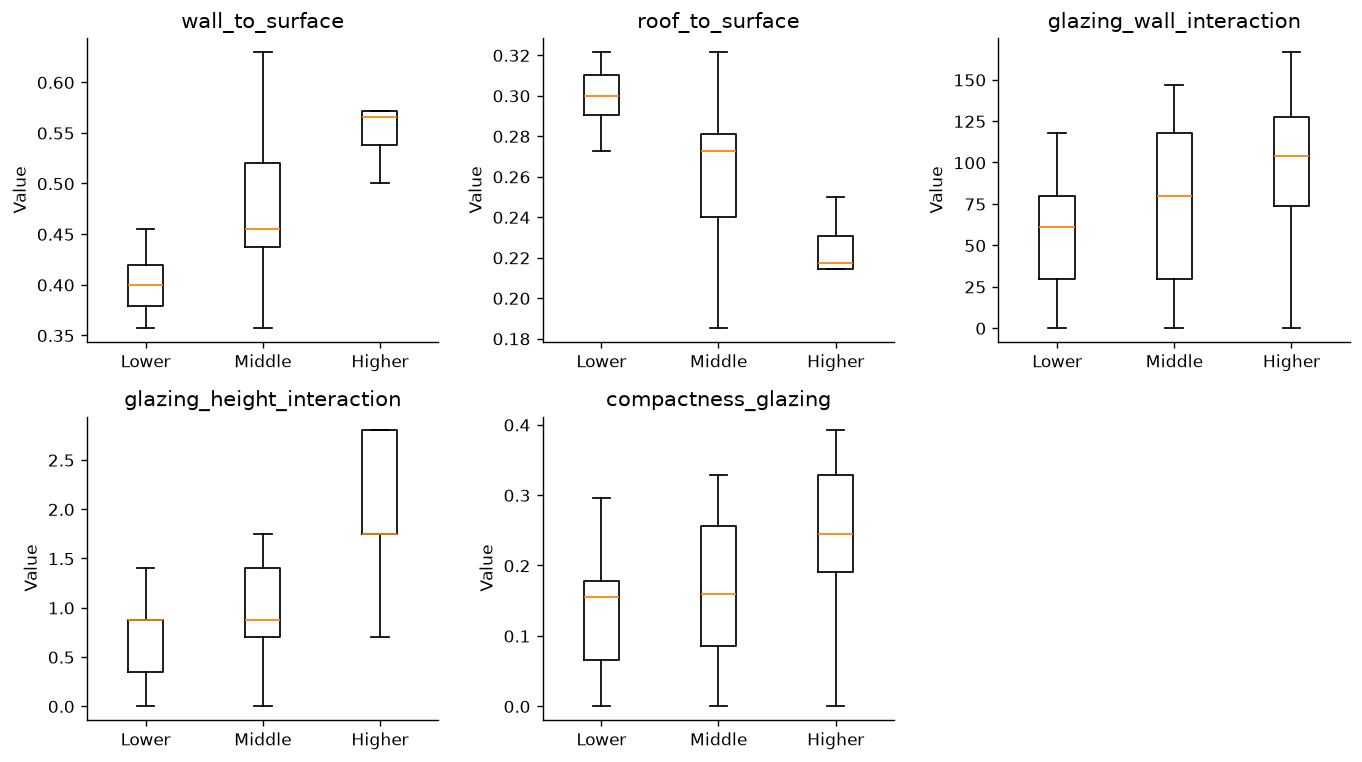

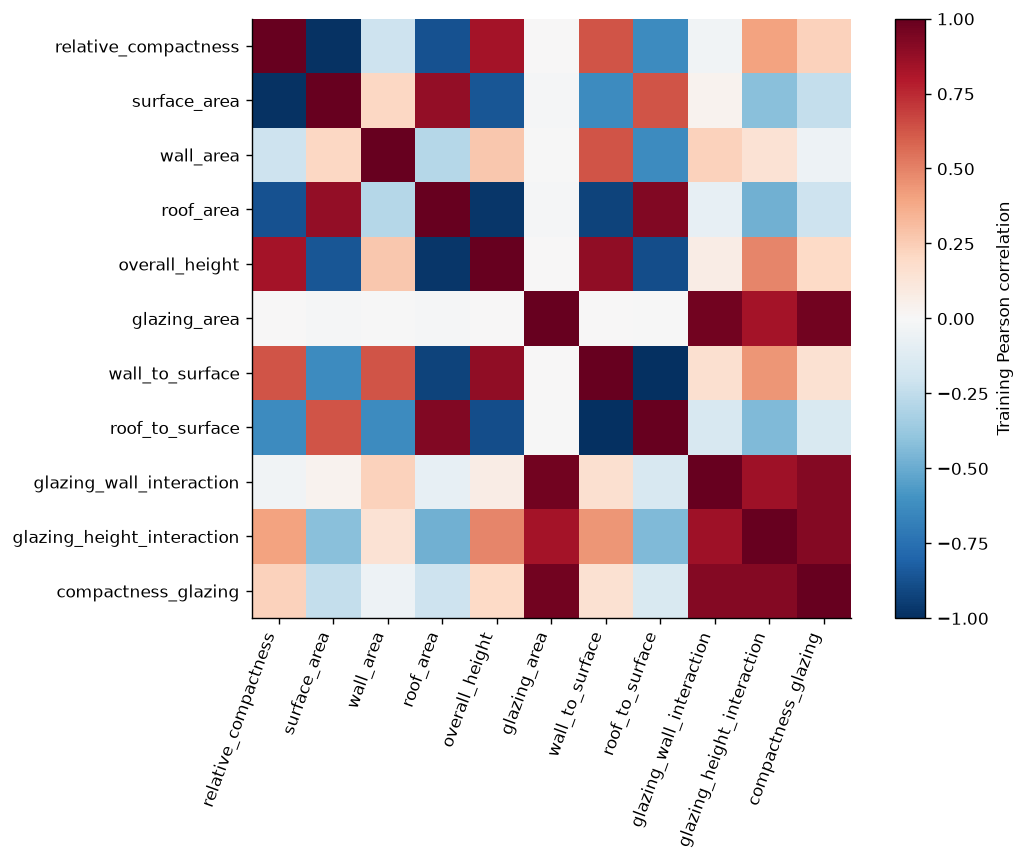

In [4]:
ENGINEERED=['wall_to_surface','roof_to_surface','glazing_wall_interaction',
    'glazing_height_interaction','compactness_glazing']
engineered_tr=BuildingEncoding(engineer=True).fit_transform(Xtr)
ALL_FEATURES=list(engineered_tr.columns)
engineer_table=pd.DataFrame({'Pearson_heating':engineered_tr[ENGINEERED].corrwith(load_tr),
    'Spearman_heating':engineered_tr[ENGINEERED].corrwith(load_tr,method='spearman'),
    'Pearson_band':engineered_tr[ENGINEERED].corrwith(ytr),
    'Minimum':engineered_tr[ENGINEERED].min(),'Maximum':engineered_tr[ENGINEERED].max()})
table(engineer_table,'feature_engineering_validation.csv')
original_corr=pd.DataFrame({'Pearson_heating':Xtr[NUMERIC].corrwith(load_tr),
    'Spearman_heating':Xtr[NUMERIC].corrwith(load_tr,method='spearman')})
table(original_corr,'training_target_correlations.csv')
corr=engineered_tr[NUMERIC+ENGINEERED].corr()
pairs=corr.where(np.triu(np.ones(corr.shape),k=1).astype(bool)).stack()
print('Strongest numerical predictor pair:',pairs.abs().idxmax(),pairs.loc[pairs.abs().idxmax()])
print('Expanded matrix rank:',np.linalg.matrix_rank(engineered_tr),'of',engineered_tr.shape[1])
fig,axes=plt.subplots(2,3,figsize=(11,6.2))
for ax,n in zip(axes.flat,ENGINEERED):
    ax.boxplot([engineered_tr.loc[ytr==i,n] for i in range(3)],tick_labels=LABELS,showfliers=False)
    ax.set(title=n,ylabel='Value')
axes.flat[-1].axis('off')
figure('04_engineered_bands')
fig,ax=plt.subplots(figsize=(9,7))
im=ax.imshow(corr,vmin=-1,vmax=1,cmap='RdBu_r')
ax.set_xticks(range(len(corr)),corr.columns,rotation=70,ha='right')
ax.set_yticks(range(len(corr)),corr.columns)
fig.colorbar(im,ax=ax,label='Training Pearson correlation')
figure('05_multicollinearity')

In [5]:
expanded_scaler=DistributionScaler().fit(engineered_tr)
expanded_audit=pd.DataFrame(expanded_scaler.audit_,index=ALL_FEATURES,
    columns=['Train_skew','IQR_flags','Scaler','Reason'])
table(expanded_audit.loc[ENGINEERED],'engineered_scaling_audit.csv')
associations=[]
for name,row in engineer_table.iterrows():
    direction='positive' if row.Pearson_heating>0 else 'negative'
    associations.append(f'- **{name}** has {direction} training association: '
        f'Pearson r={row.Pearson_heating:.3f}, Spearman rho={row.Spearman_heating:.3f}.')
note('### Training evidence for the engineered hypotheses\n\n'+'\n'.join(associations)+
    '\n\nThese related features are not independent effects. Their usefulness is tested '
    'by the controlled M2-to-M3 model comparison, rather than inferred from correlation alone.')


                            Train_skew  IQR_flags          Scaler                          Reason
wall_to_surface                 0.2139          0  StandardScaler  Moderate skew, no IQR outliers
roof_to_surface                -0.2139          0  StandardScaler  Moderate skew, no IQR outliers
glazing_wall_interaction        0.1126          0  StandardScaler  Moderate skew, no IQR outliers
glazing_height_interaction      0.6241          0  StandardScaler  Moderate skew, no IQR outliers
compactness_glazing             0.1131          0  StandardScaler  Moderate skew, no IQR outliers


### Training evidence for the engineered hypotheses

- **wall_to_surface** has positive training association: Pearson r=0.865, Spearman rho=0.855.
- **roof_to_surface** has negative training association: Pearson r=-0.865, Spearman rho=-0.855.
- **glazing_wall_interaction** has positive training association: Pearson r=0.385, Spearman rho=0.462.
- **glazing_height_interaction** has positive training association: Pearson r=0.689, Spearman rho=0.652.
- **compactness_glazing** has positive training association: Pearson r=0.425, Spearman rho=0.497.

These related features are not independent effects. Their usefulness is tested by the controlled M2-to-M3 model comparison, rather than inferred from correlation alone.

## Tasks 4-5 - Five Decision Trees and first comparison
M1 uses all original inputs with nominal encoding (16 columns) and no scaling; M2 uses
the same encoded inputs, scaled; M3 adds five engineered columns (21 total), scaled;
M4 selects K-Best five columns from the same 21 candidates, then scales; M5 uses the
identical selection rule on raw encoded/engineered columns without scaling. M4/M5 fit
the selector before scaling, ensuring identical feature names within each fold.
This adapts Studio 3's illustrative fixed-feature example to a controlled comparison.

Prespecify max_depth=6 and min_samples_leaf=5 for all trees, random_state=42. Use the
same five stratified training folds. ANOVA selection learns class relevance only inside
each training fold. Select the tree representation with the highest mean CV accuracy;
the holdout does not choose representation or tree parameters.

In [6]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(cv5.split(Xtr,ytr))
def tree_pipeline(engineer=False, select=False, scale=False):
    steps = [('prepare',BuildingEncoding(engineer=engineer))]
    if select: steps.append(('select',SelectKBest(f_classif,k=5)))
    if scale: steps.append(('scale',DistributionScaler()))
    steps.append(('model',DecisionTreeClassifier(max_depth=6,
        min_samples_leaf=5,random_state=SEED)))
    return Pipeline(steps)
trees = {
    'M1 Raw original':tree_pipeline(),
    'M2 Scaled original':tree_pipeline(scale=True),
    'M3 Engineered':tree_pipeline(engineer=True,scale=True),
    'M4 Selected scaled':tree_pipeline(engineer=True,select=True,scale=True),
    'M5 Selected raw':tree_pipeline(engineer=True,select=True)}
tree_cv, tree_fitted = {}, {}
for name, est in trees.items():
    result = cross_validate(est,Xtr,ytr,cv=folds,
        scoring={'accuracy':'accuracy','macro_f1':'f1_macro'},return_train_score=True)
    tree_cv[name] = result
    tree_fitted[name] = clone(est).fit(Xtr,ytr)
tree_cv_table = pd.DataFrame({name:{'CV_accuracy':r['test_accuracy'].mean(),
    'CV_SD':r['test_accuracy'].std(ddof=1), 'CV_macro_F1':r['test_macro_f1'].mean(),
    'CV_train_accuracy':r['train_accuracy'].mean()}
    for name,r in tree_cv.items()}).T
best_tree_name = tree_cv_table['CV_accuracy'].idxmax()
table(tree_cv_table,'tree_cv.csv')
print('Tree selected on training CV:',best_tree_name)
selected_dt = np.array(ALL_FEATURES)[tree_fitted['M4 Selected scaled'].named_steps['select'].get_support()]
print('M4/M5 training-selected features:', ', '.join(selected_dt))
assert np.array_equal(tree_fitted['M4 Selected scaled'].named_steps['select'].get_support(),
    tree_fitted['M5 Selected raw'].named_steps['select'].get_support())
fold_tree_table = pd.DataFrame({name:r['test_accuracy'] for name,r in tree_cv.items()},
    index=[f'Fold {i+1}' for i in range(5)])
table(fold_tree_table,'tree_fold_accuracy.csv')

                    CV_accuracy  CV_SD  CV_macro_F1  CV_train_accuracy
M1 Raw original          0.9069 0.0383       0.9068             0.9386
M2 Scaled original       0.9069 0.0383       0.9068             0.9386
M3 Engineered            0.9181 0.0256       0.9184             0.9502
M4 Selected scaled       0.8827 0.0380       0.8821             0.9209
M5 Selected raw          0.8827 0.0380       0.8821             0.9209
Tree selected on training CV: M3 Engineered
M4/M5 training-selected features: roof_area, overall_height, wall_to_surface, roof_to_surface, glazing_height_interaction
        M1 Raw original  M2 Scaled original  M3 Engineered  M4 Selected scaled  M5 Selected raw
Fold 1           0.8611              0.8611         0.8796              0.8426           0.8426
Fold 2           0.9352              0.9352         0.9352              0.8889           0.8889
Fold 3           0.8785              0.8785         0.9065              0.8692           0.8692
Fold 4           0.9065 

## Task 6 - SVM baseline and five-fold validation
SVC predicts the three training-defined demand bands; SVR would instead estimate
continuous heating load. Baseline SVC uses original inputs, fixed nominal encoding,
distribution-aware scaling, RBF C=1 and gamma='scale'. Save a seed-shuffled CSV for
Studio Activity 3; source_row_id, demand_band, heating_load and cooling_load never enter X.
The same 70/30 partition is used throughout. The four final SVM procedures are baseline,
tuned original inputs, tuned parameters plus K-Best, and tuned parameters plus PCA.

In [7]:
def svm_pipeline(extra=None, params=None):
    steps = [('prepare',BuildingEncoding()),('scale',DistributionScaler())]
    if extra is not None: steps.append(extra)
    steps.append(('model',SVC(cache_size=300,**(params or {}))))
    return Pipeline(steps)
baseline = svm_pipeline()
baseline_cv = cross_validate(baseline,Xtr,ytr,cv=folds,
    scoring={'accuracy':'accuracy','macro_f1':'f1_macro'})
print('Baseline accuracy folds:',np.round(baseline_cv['test_accuracy'],4))
print('Baseline mean/SD:',baseline_cv['test_accuracy'].mean(),
      baseline_cv['test_accuracy'].std(ddof=1))
dummy = DummyClassifier(strategy='most_frequent').fit(Xtr,ytr)
print('Training-CV majority baseline:',cross_val_score(
    DummyClassifier(strategy='most_frequent'),Xtr,ytr,cv=folds).mean())

Baseline accuracy folds: [0.7963 0.8611 0.8692 0.8037 0.8785]
Baseline mean/SD: 0.8417618553132572 0.03869086354911365
Training-CV majority baseline: 0.329595015576324


## Task 7 - Hyperparameter tuning with nested CV
GridSearchCV compares linear, RBF and polynomial kernels. C controls the penalty for
misclassification; gamma sets nonlinear kernel reach; degree controls polynomial order.
The 32 prespecified configurations span C=0.1,1,10,100, four gamma options for RBF and
two polynomial degrees. Accuracy is the selection metric because the assignment requests
it and classes are balanced [3]. Macro F1 is also reported. A fixed grid limits researcher
degrees of freedom; it cannot guarantee a global optimum.

In each outer training fold, a new inner five-fold grid search is run. Its selected SVM
parameters are then reused for fresh inner K-Best/PCA searches in that outer training
fold. Thus outer validation observations influence neither tuning nor transformation.
Finally the same sequence is fitted to all 537 training rows. Inner best scores are
selection statistics; nested outer scores are the reported validation estimates [3].

In [8]:
PARAM_GRID = [
    {'model__kernel':['linear'],'model__C':[.1,1,10,100]},
    {'model__kernel':['rbf'],'model__C':[.1,1,10,100],
     'model__gamma':['scale',.01,.1,1]},
    {'model__kernel':['poly'],'model__C':[.1,1,10],
     'model__gamma':['scale',.1],'model__degree':[2,3]}]
print('Number of SVM grid configurations:',sum(
    np.prod([len(v) for v in g.values()]) for g in PARAM_GRID))
def fit_svm_sequence(A,b,seed):
    inner = StratifiedKFold(n_splits=5,shuffle=True,random_state=seed)
    search = GridSearchCV(svm_pipeline(),PARAM_GRID,cv=inner,
        scoring='accuracy',refit=True,n_jobs=1,error_score='raise')
    search.fit(A,b)
    params = {k.removeprefix('model__'):v for k,v in search.best_params_.items()}
    selection = GridSearchCV(svm_pipeline(('select',SelectKBest(f_classif)),params),
        {'select__k':[5,10,14]},cv=inner,scoring='accuracy',n_jobs=1,error_score='raise')
    selection.fit(A,b)
    reduction = GridSearchCV(svm_pipeline(('pca',PCA(svd_solver='full')),params),
        {'pca__n_components':[.90,.95,.99]},cv=inner,scoring='accuracy',
        n_jobs=1,error_score='raise')
    reduction.fit(A,b)
    return search,selection,reduction

SVM_NAMES = ['S1 Baseline','S2 Tuned','S3 K-Best','S4 PCA']
nested_acc = {n:[] for n in SVM_NAMES}
nested_f1 = {n:[] for n in SVM_NAMES}
outer_parameters = []
start = time.perf_counter()
for f,(a,b) in enumerate(folds):
    A,B = Xtr.iloc[a],Xtr.iloc[b]
    ya,yb = ytr.iloc[a],ytr.iloc[b]
    gs,ks,ps = fit_svm_sequence(A,ya,SEED+f+1)
    estimators = [clone(baseline).fit(A,ya),gs.best_estimator_,
        ks.best_estimator_,ps.best_estimator_]
    for name,est in zip(SVM_NAMES,estimators):
        pred = est.predict(B)
        nested_acc[name].append(accuracy_score(yb,pred))
        nested_f1[name].append(f1_score(yb,pred,average='macro'))
    outer_parameters.append({'fold':f+1,'svm':gs.best_params_,
        'k':ks.best_params_,'pca':ps.best_params_})
    print(f'Outer fold {f+1}/5 complete: {gs.best_params_}')
search, ksearch, psearch = fit_svm_sequence(Xtr,ytr,SEED)
svm_fitted = dict(zip(SVM_NAMES,[clone(baseline).fit(Xtr,ytr),
    search.best_estimator_,ksearch.best_estimator_,psearch.best_estimator_]))
svm_cv_table = pd.DataFrame({n:{'CV_accuracy':np.mean(nested_acc[n]),
    'CV_SD':np.std(nested_acc[n],ddof=1),'CV_macro_F1':np.mean(nested_f1[n])}
    for n in SVM_NAMES}).T
best_svm_name = svm_cv_table['CV_accuracy'].idxmax()
table(svm_cv_table,'svm_nested_cv.csv')
table(pd.DataFrame(nested_acc,index=[f'Fold {i+1}' for i in range(5)]),
    'svm_outer_fold_accuracy.csv')
print('Full-training best SVM parameters:',search.best_params_)
print('Inner best score (selection only):',search.best_score_)
print('SVM procedure selected on nested training CV:',best_svm_name)
print('Elapsed seconds:',round(time.perf_counter()-start,1))
grid_table = pd.DataFrame(search.cv_results_)[['params','mean_test_score',
    'std_test_score','rank_test_score']].sort_values('rank_test_score')
grid_table.to_csv(OUT / 'svm_grid_search.csv',index=False)
table(grid_table.head(6))

Number of SVM grid configurations: 32


Outer fold 1/5 complete: {'model__C': 100, 'model__gamma': 'scale', 'model__kernel': 'rbf'}


Outer fold 2/5 complete: {'model__C': 100, 'model__gamma': 'scale', 'model__kernel': 'rbf'}


Outer fold 3/5 complete: {'model__C': 100, 'model__gamma': 'scale', 'model__kernel': 'rbf'}


Outer fold 4/5 complete: {'model__C': 100, 'model__gamma': 'scale', 'model__kernel': 'rbf'}


Outer fold 5/5 complete: {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'rbf'}


             CV_accuracy  CV_SD  CV_macro_F1
S1 Baseline       0.8418 0.0387       0.8382
S2 Tuned          0.8659 0.0528       0.8657
S3 K-Best         0.9236 0.0334       0.9232
S4 PCA            0.8939 0.0267       0.8937
        S1 Baseline  S2 Tuned  S3 K-Best  S4 PCA
Fold 1       0.7963    0.8611     0.9259  0.8611
Fold 2       0.8611    0.8981     0.9722  0.9259
Fold 3       0.8692    0.9252     0.9346  0.9159
Fold 4       0.8037    0.8598     0.8879  0.8879
Fold 5       0.8785    0.7850     0.8972  0.8785
Full-training best SVM parameters: {'model__C': 100, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
Inner best score (selection only): 0.8976462443752163
SVM procedure selected on nested training CV: S3 K-Best
Elapsed seconds: 29.9
                                                                                   params  mean_test_score  std_test_score  rank_test_score
16                     {'model__C': 100, 'model__gamma': 'scale', 'model__kernel': 'rbf'}           0.8976 

## Task 8 - K-Best selection
ANOVA F compares between-class and within-class variation. Search k in {5,10,14} from
the 16 encoded original inputs, reusing the tuned SVM parameters as Studio 3 requests.
The full 16-column tuned model is already a separate comparator. The chosen k and names
are shown below; selection is repeated inside each outer training fold. One-hot indicators
are interpretable nominal effects, but a selected subset can omit categories/interactions.
ANOVA is a relevance heuristic rather than a causal test or multicollinearity solution.

                   Feature  ANOVA_F  Selected
4           overall_height 539.0352      True
3                roof_area 489.3580      True
1             surface_area 159.0577      True
0     relative_compactness 141.1911      True
2                wall_area  60.2537      True
5             glazing_area  28.9372      True
10  glazing_distribution_0   4.1044      True
11  glazing_distribution_1   1.9616      True
15  glazing_distribution_5   1.1911      True
13  glazing_distribution_3   1.0926      True
14  glazing_distribution_4   0.8342     False
8            orientation_4   0.7835     False
12  glazing_distribution_2   0.3884     False
7            orientation_3   0.2955     False
9            orientation_5   0.1199     False
6            orientation_2  -0.0000     False
Selected k: 10
Selected names: relative_compactness, surface_area, wall_area, roof_area, overall_height, glazing_area, glazing_distribution_0, glazing_distribution_1, glazing_distribution_3, glazing_distribution_5
Inne

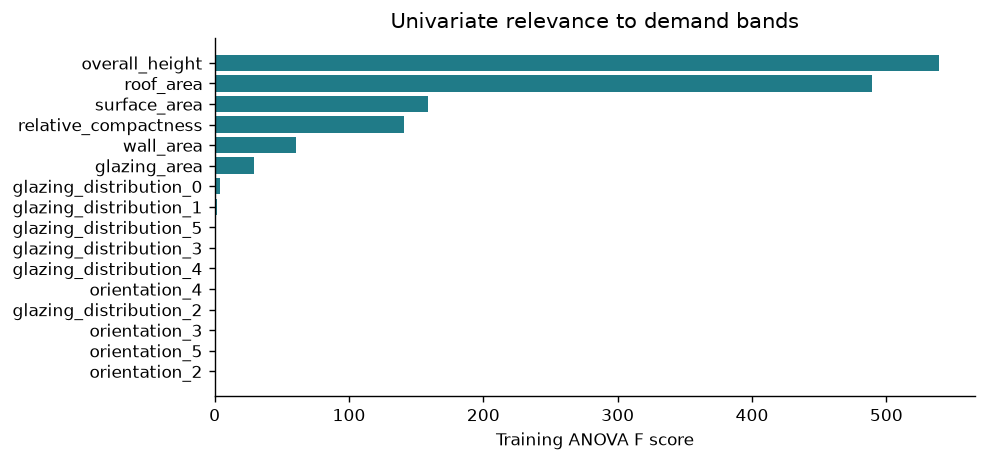

In [9]:
kbest = ksearch.best_estimator_.named_steps['select']
k_features = np.array(ENCODED_FEATURES)[kbest.get_support()]
k_table = pd.DataFrame({'Feature':ENCODED_FEATURES,'ANOVA_F':kbest.scores_,
    'Selected':kbest.get_support()}).sort_values('ANOVA_F',ascending=False)
table(k_table,'svm_selected_features.csv')
print('Selected k:',ksearch.best_params_['select__k'])
print('Selected names:',', '.join(k_features))
print('Inner CV results for k:',[(p['select__k'],round(s,4)) for p,s in zip(
    ksearch.cv_results_['params'],ksearch.cv_results_['mean_test_score'])])
fig,ax = plt.subplots(figsize=(8,3.8))
ax.barh(k_table.Feature[::-1],k_table.ANOVA_F[::-1],color='#207b88')
ax.set(xlabel='Training ANOVA F score',title='Univariate relevance to demand bands')
figure('05_kbest')

## Task 9 - Dimensionality reduction with PCA
After nominal encoding, the original eight inputs produce 16 columns. Inner CV chooses
a retained-variance threshold of 90%, 95% or 99% rather than assuming ten useful
components. This follows Studio 3's explicit dataset-dependent allowance. PCA fits after
training-fold scaling and centring, then transforms validation/test with those components.
It preserves input variance rather than class separation; a low-variance direction may
still predict demand. One-hot indicator dependencies and geometric redundancy reduce
rank. The fitted component count, variance and loadings are documented below [3].

    Component  Explained_variance  Cumulative
0           1              0.4892      0.4892
1           2              0.1640      0.6533
2           3              0.1344      0.7877
3           4              0.0344      0.8221
4           5              0.0330      0.8550
5           6              0.0320      0.8871
6           7              0.0266      0.9137
7           8              0.0249      0.9386
8           9              0.0239      0.9625
9          10              0.0227      0.9852
10         11              0.0074      0.9926
11         12              0.0068      0.9994
12         13              0.0006      1.0000
13         14              0.0000      1.0000
14         15              0.0000      1.0000
15         16              0.0000      1.0000
Chosen variance threshold: 0.9
Retained components: 7
Retained variance: 0.9136707633979284
                           PC1     PC2     PC3     PC4     PC5     PC6     PC7
relative_compactness   -0.4965 -0.2407 -0.0111 

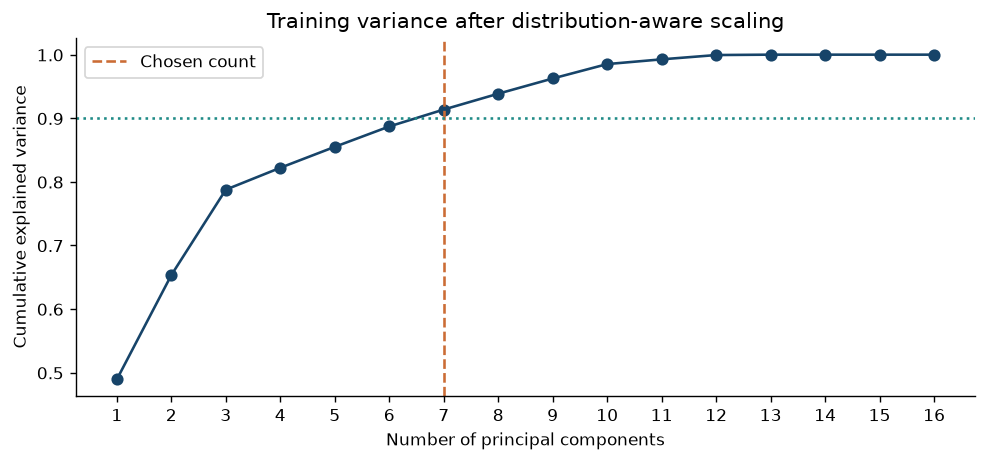

In [10]:
pca = psearch.best_estimator_.named_steps['pca']
full_pca = PCA(svd_solver='full').fit(scaler.transform(encoded_tr))
pca_table = pd.DataFrame({'Component':np.arange(1,17),
    'Explained_variance':full_pca.explained_variance_ratio_,
    'Cumulative':np.cumsum(full_pca.explained_variance_ratio_)})
table(pca_table,'pca_variance.csv')
print('Chosen variance threshold:',psearch.best_params_['pca__n_components'])
print('Retained components:',pca.n_components_)
print('Retained variance:',pca.explained_variance_ratio_.sum())
loadings = pd.DataFrame(pca.components_.T,index=ENCODED_FEATURES,
    columns=[f'PC{i+1}' for i in range(pca.n_components_)])
table(loadings,'pca_loadings.csv')
fig,ax=plt.subplots(figsize=(8,3.8))
ax.plot(pca_table.Component,pca_table.Cumulative,'o-',color='#174469')
ax.axvline(pca.n_components_,linestyle='--',color='#cb6c35',label='Chosen count')
ax.axhline(psearch.best_params_['pca__n_components'],linestyle=':',color='#208b87')
ax.set(xlabel='Number of principal components',ylabel='Cumulative explained variance',
    title='Training variance after distribution-aware scaling',xticks=range(1,17))
ax.legend()
figure('06_pca_variance')

## Task 10 - Locked comparison and holdout results
The winning tree and SVM procedure have now been selected using training CV. Test scores
below are computed for reporting after all configurations are fixed. They are not used
to choose k, kernels, parameters or components, or to change the selected procedure.
The test contains 231 rows; one correct/incorrect prediction changes accuracy by about
0.43 percentage points. All test metrics are empirical, not deployment guarantees.

                    CV_accuracy  CV_SD  CV_macro_F1  CV_train_accuracy  Test_accuracy  Test_macro_precision  Test_macro_recall  Test_macro_F1  Train_accuracy
M1 Raw original          0.9069 0.0383       0.9068             0.9386         0.9351                0.9416             0.9336         0.9339          0.9404
M2 Scaled original       0.9069 0.0383       0.9068             0.9386         0.9351                0.9416             0.9336         0.9339          0.9404
M3 Engineered            0.9181 0.0256       0.9184             0.9502         0.9524                0.9567             0.9518         0.9516          0.9479
M4 Selected scaled       0.8827 0.0380       0.8821             0.9209         0.9221                0.9260             0.9205         0.9175          0.9162
M5 Selected raw          0.8827 0.0380       0.8821             0.9209         0.9221                0.9260             0.9205         0.9175          0.9162
             CV_accuracy  CV_SD  CV_macro_F1  Test_a

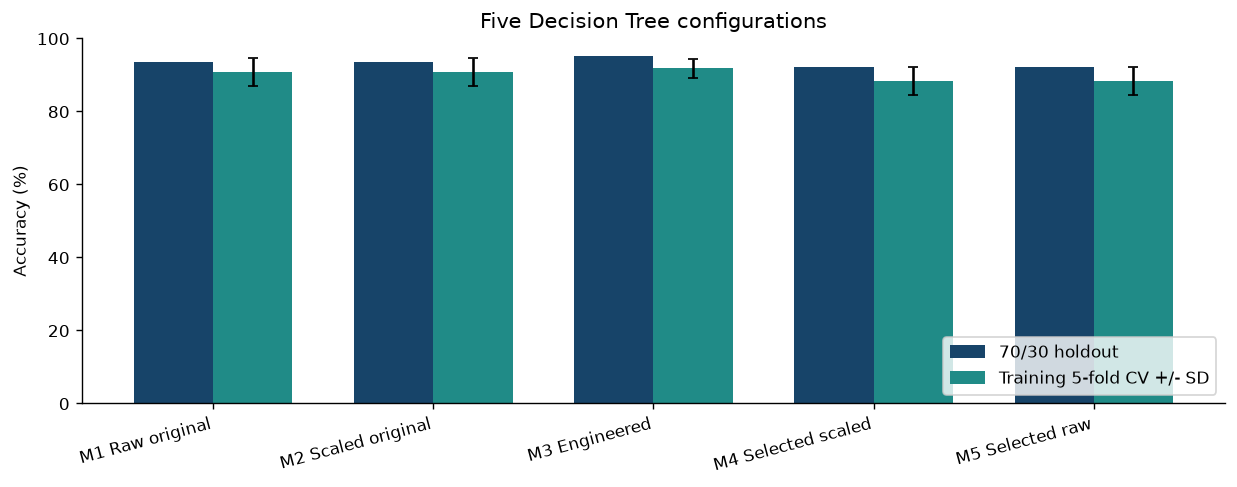

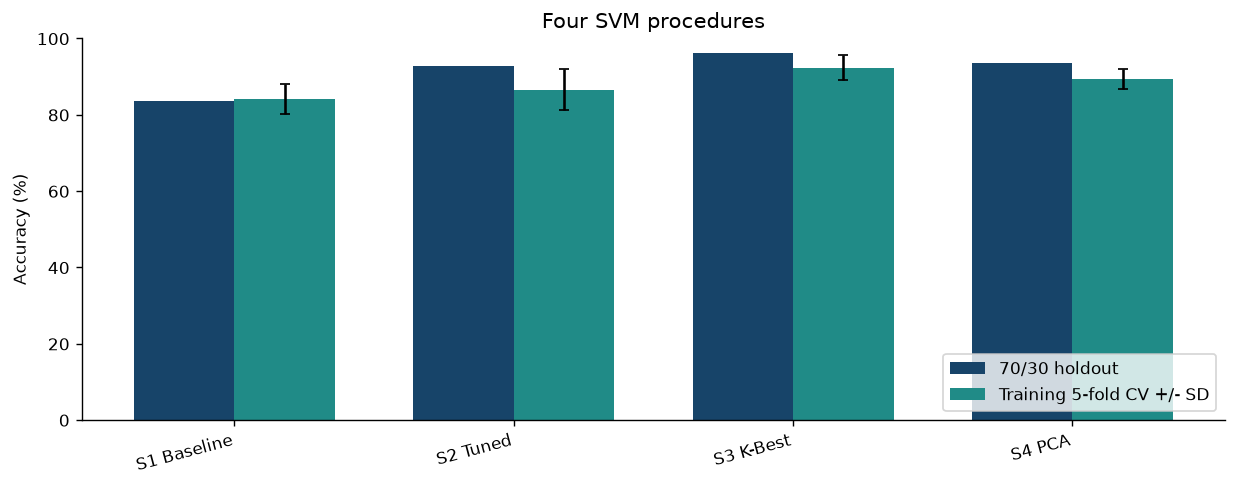

In [11]:
def holdout_metrics(est):
    pred=est.predict(Xte)
    return {'Test_accuracy':accuracy_score(yte,pred),
        'Test_macro_precision':precision_score(yte,pred,average='macro',zero_division=0),
        'Test_macro_recall':recall_score(yte,pred,average='macro',zero_division=0),
        'Test_macro_F1':f1_score(yte,pred,average='macro'),
        'Train_accuracy':accuracy_score(ytr,est.predict(Xtr))}
tree_final=tree_cv_table.join(pd.DataFrame(
    {n:holdout_metrics(e) for n,e in tree_fitted.items()}).T)
svm_final=svm_cv_table.join(pd.DataFrame(
    {n:holdout_metrics(e) for n,e in svm_fitted.items()}).T)
table(tree_final,'first_comparison_table.csv')
table(svm_final,'final_comparison_table.csv')
print('Majority-class holdout accuracy:',accuracy_score(yte,dummy.predict(Xte)))
for frame,name,title in [(tree_final,'07_tree_comparison','Five Decision Tree configurations'),
    (svm_final,'08_svm_comparison','Four SVM procedures')]:
    fig,ax=plt.subplots(figsize=(10,4))
    xx=np.arange(len(frame))
    ax.bar(xx-.18,frame.Test_accuracy*100,.36,color='#174469',label='70/30 holdout')
    ax.bar(xx+.18,frame.CV_accuracy*100,.36,yerr=frame.CV_SD*100,
        capsize=3,color='#208b87',label='Training 5-fold CV +/- SD')
    ax.set_xticks(xx,frame.index,rotation=15,ha='right')
    ax.set(ylabel='Accuracy (%)',ylim=(0,100),title=title)
    ax.legend(loc='lower right')
    figure(name)
predictions=pd.DataFrame({'source_row_id':test_idx,'Actual':yte.to_numpy()})
for n,e in {**tree_fitted,**svm_fitted}.items(): predictions[n]=e.predict(Xte)
predictions.to_csv(OUT/'holdout_predictions.csv',index=False)

### Comparison tables at a glance

Accuracy is shown in percent; SD is fold variation. SVM validation uses nested folds. Detailed metrics remain in the complete tables above.

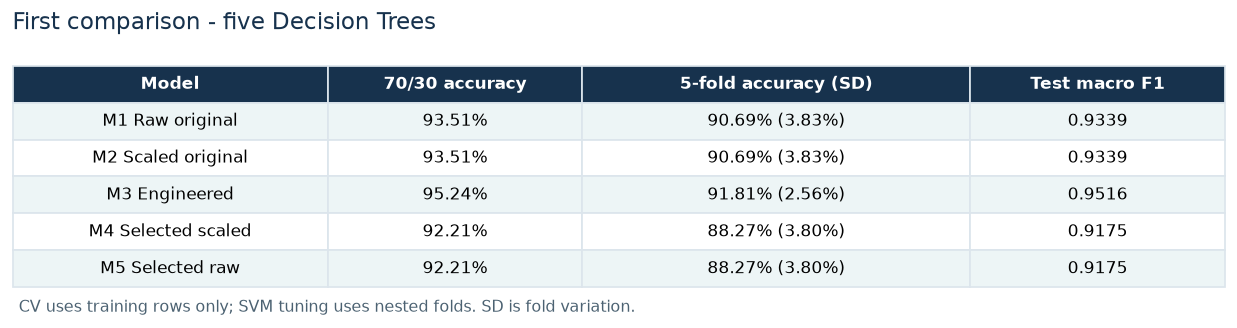

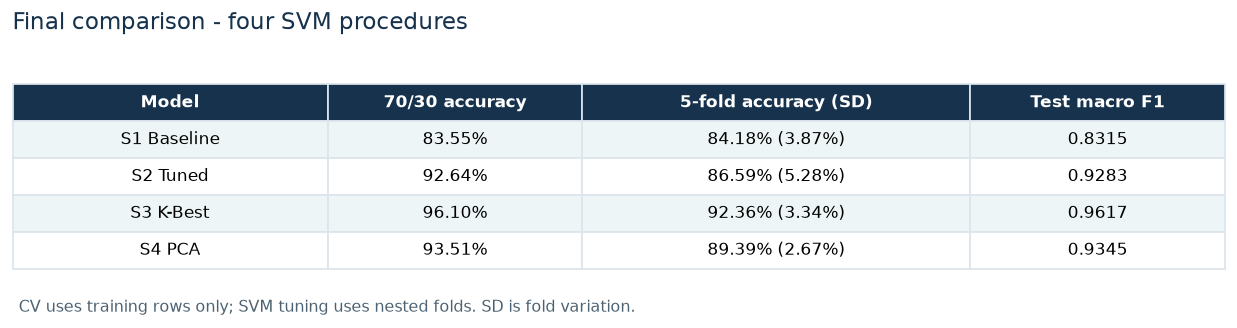

In [12]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
root = Path.cwd()
if not (root / 'data/energy_data.csv').exists():
    root = root / 'portfolio2_energy'
for filename, title, figname in [
    ('first_comparison_table.csv', 'First comparison - five Decision Trees', '11_tree_table'),
    ('final_comparison_table.csv', 'Final comparison - four SVM procedures', '12_svm_table')]:
    results = pd.read_csv(root / 'output' / filename, index_col=0)
    compact = pd.DataFrame({
        'Model': results.index,
        '70/30 accuracy': [f'{v:.2%}' for v in results.Test_accuracy],
        '5-fold accuracy (SD)': [f'{m:.2%} ({s:.2%})' for m, s in
            zip(results.CV_accuracy, results.CV_SD)],
        'Test macro F1': [f'{v:.4f}' for v in results.Test_macro_F1]})
    fig, ax = plt.subplots(figsize=(10, 2.6))
    ax.axis('off')
    ax.set_title(title, fontsize=13, loc='left', pad=14, color='#17324D')
    tab = ax.table(cellText=compact.values, colLabels=compact.columns,
        cellLoc='center', loc='center', colWidths=[.26,.21,.32,.21])
    tab.auto_set_font_size(False)
    tab.set_fontsize(10)
    tab.scale(1, 1.8)
    for (row, col), cell in tab.get_celld().items():
        cell.set_edgecolor('#DCE5EC')
        if row == 0:
            cell.set_facecolor('#17324D')
            cell.set_text_props(color='white', weight='bold')
        else:
            cell.set_facecolor('#EDF5F6' if row % 2 else 'white')
    fig.text(.02,.02,'CV uses training rows only; SVM tuning uses nested folds. SD is fold variation.',
        fontsize=9, color='#4C6272')
    fig.tight_layout()
    fig.savefig(root/'output/figures'/f'{figname}.png',dpi=180,bbox_inches='tight')
    plt.show()
    plt.close(fig)


### First-table reflections - Studio Activity 2
The answers use percentage-point differences, with CV as the basis for selecting models.
Tree scaling comparisons hold the inputs and tree settings constant. A difference after
scaling may arise from numerical precision or threshold ties; it should not be attributed
to changing class information.

In [13]:
def pp(a,b): return (a-b)*100
tc=tree_final
note(f"""1. **Which feature set performed best?** Training CV selects **{best_tree_name}**
with {tc.loc[best_tree_name,'CV_accuracy']:.2%} accuracy (SD
{tc.loc[best_tree_name,'CV_SD']:.2%}); its holdout accuracy is
{tc.loc[best_tree_name,'Test_accuracy']:.2%}. This is empirical evidence for this split,
not proof that it is universally best.

2. **Did normalisation improve performance (M1 vs M2)?** The CV change is
{pp(tc.iloc[1].CV_accuracy,tc.iloc[0].CV_accuracy):+.2f} percentage points and holdout change
{pp(tc.iloc[1].Test_accuracy,tc.iloc[0].Test_accuracy):+.2f} points. Monotone scaling usually
preserves tree partitions; small changes can reflect floating-point split selection.

3. **Did engineering help (M2 vs M3)?** CV changes by
{pp(tc.iloc[2].CV_accuracy,tc.iloc[1].CV_accuracy):+.2f} points and holdout by
{pp(tc.iloc[2].Test_accuracy,tc.iloc[1].Test_accuracy):+.2f} points. Envelope composition and glazing interactions
offer engineering structure, but extra columns can also add redundant split options.
The observed change concerns trees, not an untested engineered SVM.

4. **Was selection effective (M3 vs M4)?** Reducing 21 candidates to 5 changes CV by
{pp(tc.iloc[3].CV_accuracy,tc.iloc[2].CV_accuracy):+.2f} points and holdout by
{pp(tc.iloc[3].Test_accuracy,tc.iloc[2].Test_accuracy):+.2f} points. ANOVA ranks individual
class separation and may discard interactions or substitute information.

5. **Is normalisation always necessary (M4 vs M5)?** With identical selected training
columns, scaled minus raw CV is {pp(tc.iloc[3].CV_accuracy,tc.iloc[4].CV_accuracy):+.2f}
points and holdout is {pp(tc.iloc[3].Test_accuracy,tc.iloc[4].Test_accuracy):+.2f} points.
This checks the tree's scale invariance; it cannot justify omitting SVM scaling.

6. **Overall pattern?** Representation and feature removal affect what a shallow tree can
partition. The CV accuracy range is {tc.CV_accuracy.min():.2%}-{tc.CV_accuracy.max():.2%}.
Train-CV gaps in the first table reveal residual overfitting. Correlated inputs make
single-feature importance unstable; the next diagnostic is conditional on the fitted tree.
""")

1. **Which feature set performed best?** Training CV selects **M3 Engineered**
with 91.81% accuracy (SD
2.56%); its holdout accuracy is
95.24%. This is empirical evidence for this split,
not proof that it is universally best.

2. **Did normalisation improve performance (M1 vs M2)?** The CV change is
+0.00 percentage points and holdout change
+0.00 points. Monotone scaling usually
preserves tree partitions; small changes can reflect floating-point split selection.

3. **Did engineering help (M2 vs M3)?** CV changes by
+1.12 points and holdout by
+1.73 points. Envelope composition and glazing interactions
offer engineering structure, but extra columns can also add redundant split options.
The observed change concerns trees, not an untested engineered SVM.

4. **Was selection effective (M3 vs M4)?** Reducing 21 candidates to 5 changes CV by
-3.54 points and holdout by
-3.03 points. ANOVA ranks individual
class separation and may discard interactions or substitute information.

5. **Is normalisation always necessary (M4 vs M5)?** With identical selected training
columns, scaled minus raw CV is +0.00
points and holdout is +0.00 points.
This checks the tree's scale invariance; it cannot justify omitting SVM scaling.

6. **Overall pattern?** Representation and feature removal affect what a shallow tree can
partition. The CV accuracy range is 88.27%-91.81%.
Train-CV gaps in the first table reveal residual overfitting. Correlated inputs make
single-feature importance unstable; the next diagnostic is conditional on the fitted tree.


In [14]:
winner=tree_fitted[best_tree_name]
winner_names=np.array(ALL_FEATURES if winner.named_steps['prepare'].engineer else ENCODED_FEATURES)
if 'select' in winner.named_steps:
    winner_names=winner_names[winner.named_steps['select'].get_support()]
meaning={
    'M1 Raw original':'The original encoded inputs retain all design variables without scaling.',
    'M2 Scaled original':'All original encoded inputs are retained; scaling preserves their information.',
    'M3 Engineered':'Envelope proportions and glazing interactions offer direct split candidates for a depth-limited tree.',
    'M4 Selected scaled':'Univariate selection concentrates class-relevant split candidates, while risking discarded interactions.',
    'M5 Selected raw':'The selected representation retains direct thresholds without changing their units.'}
note('**Why the selected tree representation is plausible:** '+meaning[best_tree_name]+
    ' The selected configuration uses '+str(len(winner_names))+' columns: '+
    ', '.join(winner_names)+'. This interpretation follows the observed CV result; '
    'it does not establish a causal or universally optimal representation.')


**Why the selected tree representation is plausible:** Envelope proportions and glazing interactions offer direct split candidates for a depth-limited tree. The selected configuration uses 21 columns: relative_compactness, surface_area, wall_area, roof_area, overall_height, glazing_area, wall_to_surface, roof_to_surface, glazing_wall_interaction, glazing_height_interaction, compactness_glazing, orientation_2, orientation_3, orientation_4, orientation_5, glazing_distribution_0, glazing_distribution_1, glazing_distribution_2, glazing_distribution_3, glazing_distribution_4, glazing_distribution_5. This interpretation follows the observed CV result; it does not establish a causal or universally optimal representation.

### Best-tree interpretation and error analysis
Impurity importance measures split usage and can favour predictors with many possible
split points. A separate diagnostic permutes each original input column in the holdout
ten times through the complete pipeline. It is not used for model tuning. Correlated
geometry can substitute for other inputs, and permutations may form unrealistic building
configurations. These importances describe the fitted classifier, not causal energy effects.

                            Impurity_importance
glazing_wall_interaction                 0.3839
overall_height                           0.3732
roof_to_surface                          0.0838
compactness_glazing                      0.0745
surface_area                             0.0245
glazing_distribution_3                   0.0166
wall_area                                0.0126
glazing_distribution_5                   0.0120
roof_area                                0.0070
orientation_4                            0.0066
glazing_area                             0.0025
orientation_3                            0.0019
wall_to_surface                          0.0006
glazing_distribution_2                   0.0002
relative_compactness                     0.0000
orientation_2                            0.0000
glazing_height_interaction               0.0000
glazing_distribution_1                   0.0000
glazing_distribution_0                   0.0000
orientation_5                           

                      Mean_accuracy_drop     SD
orientation                       0.0030 0.0067
relative_compactness              0.0121 0.0069
glazing_distribution              0.0195 0.0080
roof_area                         0.0675 0.0118
wall_area                         0.1121 0.0140
surface_area                      0.1394 0.0167
glazing_area                      0.2173 0.0161
overall_height                    0.4693 0.0337


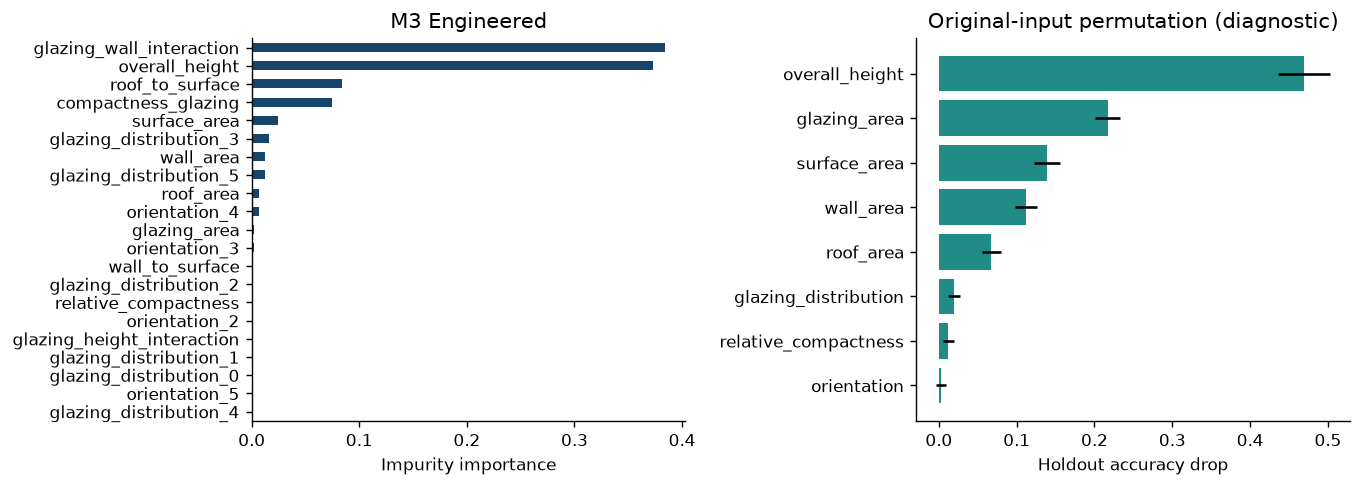

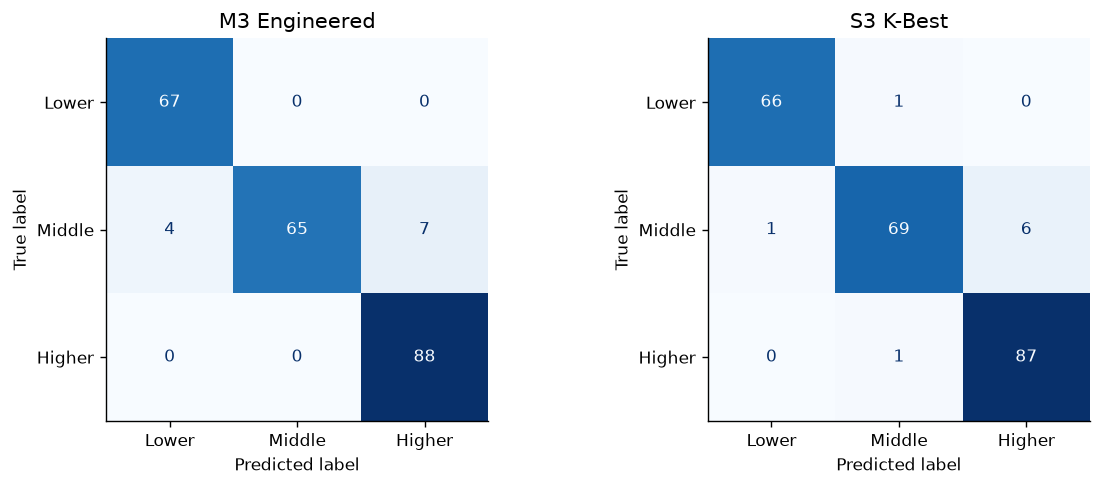

Selected SVM holdout classification report
              precision    recall  f1-score   support

       Lower     0.9851    0.9851    0.9851        67
      Middle     0.9718    0.9079    0.9388        76
      Higher     0.9355    0.9886    0.9613        88

    accuracy                         0.9610       231
   macro avg     0.9641    0.9605    0.9617       231
weighted avg     0.9618    0.9610    0.9608       231



In [15]:
best_tree=tree_fitted[best_tree_name]
names=np.array(ALL_FEATURES if best_tree.named_steps['prepare'].engineer else ENCODED_FEATURES)
if 'select' in best_tree.named_steps:
    names=names[best_tree.named_steps['select'].get_support()]
impurity=pd.Series(best_tree.named_steps['model'].feature_importances_,
    index=names,name='Impurity_importance').sort_values(ascending=False)
table(impurity.to_frame(),'tree_importance.csv')
permuted=permutation_importance(best_tree,Xte,yte,n_repeats=10,
    random_state=SEED,scoring='accuracy',n_jobs=1)
permutation=pd.DataFrame({'Mean_accuracy_drop':permuted.importances_mean,
    'SD':permuted.importances_std},index=ORIGINAL).sort_values('Mean_accuracy_drop')
table(permutation,'tree_permutation.csv')
fig,axes=plt.subplots(1,2,figsize=(11,4))
impurity.iloc[::-1].plot.barh(ax=axes[0],color='#174469')
axes[0].set(xlabel='Impurity importance',title=best_tree_name)
axes[1].barh(permutation.index,permutation.Mean_accuracy_drop,
    xerr=permutation.SD,color='#208b87')
axes[1].set(xlabel='Holdout accuracy drop',title='Original-input permutation (diagnostic)')
figure('09_tree_importance')
best_svm=svm_fitted[best_svm_name]
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,(n,e) in zip(axes,[(best_tree_name,best_tree),(best_svm_name,best_svm)]):
    ConfusionMatrixDisplay.from_estimator(e,Xte,yte,display_labels=LABELS,
        cmap='Blues',ax=ax,colorbar=False)
    ax.set_title(n)
figure('10_confusion_matrices')
print('Selected SVM holdout classification report')
print(classification_report(yte,best_svm.predict(Xte),target_names=LABELS,digits=4))

### Additional validation - unseen building geometries
Cases share 12 underlying geometries while varying orientation and glazing. A row split
can therefore contain related cases on both sides. Define a group from the first five
geometry inputs, excluding orientation, glazing and responses. StratifiedGroupKFold
holds out complete geometries among training observations. The CV-selected tree is fixed;
the selected SVM procedure is retuned with grouped inner folds. No geometry crosses a
grouped train/validation boundary. With only 12 geometries, grouped fold estimates can
vary substantially. This is a harder sensitivity check, not an external-site benchmark.

In [16]:
geometry = X[ORIGINAL[:5]].apply(tuple,axis=1)
groups=pd.Series(pd.factorize(geometry)[0],index=X.index)
gtr=groups.iloc[train_idx].to_numpy()
gtest=groups.iloc[test_idx].to_numpy()
overlap=set(gtr)&set(gtest)
print('Total unique building geometries:',groups.nunique())
print('Geometries shared across row train/test:',len(overlap))
print('Holdout rows whose geometry appears in training:',np.isin(gtest,list(overlap)).sum())
group_cv=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED)
group_folds=list(group_cv.split(Xtr,ytr,gtr))
group_tree_scores=[]
group_svm_scores=[]
group_details=[]
for f,(a,b) in enumerate(group_folds):
    assert not set(gtr[a])&set(gtr[b])
    A,B,ya,yb=Xtr.iloc[a],Xtr.iloc[b],ytr.iloc[a],ytr.iloc[b]
    tree=clone(trees[best_tree_name]).fit(A,ya)
    group_tree_scores.append(accuracy_score(yb,tree.predict(B)))
    if best_svm_name=='S1 Baseline':
        est=clone(baseline).fit(A,ya)
    else:
        inner=list(StratifiedGroupKFold(n_splits=5,shuffle=True,
            random_state=SEED+f+1).split(A,ya,gtr[a]))
        gs=GridSearchCV(svm_pipeline(),PARAM_GRID,cv=inner,
            scoring='accuracy',n_jobs=1,error_score='raise').fit(A,ya)
        est=gs.best_estimator_
        params={k.removeprefix('model__'):v for k,v in gs.best_params_.items()}
        if best_svm_name=='S3 K-Best':
            est=GridSearchCV(svm_pipeline(('select',SelectKBest(f_classif)),params),
                {'select__k':[5,10,14]},cv=inner,scoring='accuracy',n_jobs=1).fit(A,ya).best_estimator_
        elif best_svm_name=='S4 PCA':
            est=GridSearchCV(svm_pipeline(('pca',PCA(svd_solver='full')),params),
                {'pca__n_components':[.90,.95,.99]},cv=inner,scoring='accuracy',n_jobs=1).fit(A,ya).best_estimator_
    group_svm_scores.append(accuracy_score(yb,est.predict(B)))
    group_details.append({'fold':f+1,'train_groups':len(set(gtr[a])),
        'validation_groups':len(set(gtr[b])),'overlap':0,
        'tree_accuracy':group_tree_scores[-1],'svm_accuracy':group_svm_scores[-1]})
    print(f'Grouped outer fold {f+1}/5 complete')
group_table=pd.DataFrame(group_details).set_index('fold')
table(group_table,'group_validation.csv')
note(f"""Geometry-group mean accuracy is **{np.mean(group_tree_scores):.2%}**
(SD {np.std(group_tree_scores,ddof=1):.2%}) for {best_tree_name} and
**{np.mean(group_svm_scores):.2%}** (SD {np.std(group_svm_scores,ddof=1):.2%}) for
{best_svm_name}. Row-based CV for those choices was
{tree_final.loc[best_tree_name,'CV_accuracy']:.2%} and
{svm_final.loc[best_svm_name,'CV_accuracy']:.2%}. Changes reflect a different evaluation
target and sampling variability; they do not prove that all row-based performance is leakage.
For unseen building geometries, prioritise geometry-separated validation and obtain independent building data.
""")

Total unique building geometries: 12
Geometries shared across row train/test: 12
Holdout rows whose geometry appears in training: 231


Grouped outer fold 1/5 complete


Grouped outer fold 2/5 complete


Grouped outer fold 3/5 complete


Grouped outer fold 4/5 complete


Grouped outer fold 5/5 complete
      train_groups  validation_groups  overlap  tree_accuracy  svm_accuracy
fold                                                                       
1               10                  2        0         0.6092        0.7586
2               10                  2        0         0.5745        0.6596
3                9                  3        0         0.6838        0.5662
4                9                  3        0         0.7259        0.5778
5               10                  2        0         0.6706        0.8706


Geometry-group mean accuracy is **65.28%**
(SD 6.05%) for M3 Engineered and
**68.65%** (SD 12.86%) for
S3 K-Best. Row-based CV for those choices was
91.81% and
92.36%. Changes reflect a different evaluation
target and sampling variability; they do not prove that all row-based performance is leakage.
For unseen building geometries, prioritise geometry-separated validation and obtain independent building data.


### Final-table reflections - Studio Activity 7
No paired significance test is prespecified; "improvement" here means an observed score
change. Fold SDs overlap in many practical comparisons and should temper conclusions.
The selected SVM procedure is the one chosen on training CV even if another happens to
obtain a higher holdout score.

In [17]:
sf=svm_final
cv_gain=pp(sf.loc['S2 Tuned','CV_accuracy'],sf.loc['S1 Baseline','CV_accuracy'])
test_gain=pp(sf.loc['S2 Tuned','Test_accuracy'],sf.loc['S1 Baseline','Test_accuracy'])
note(f"""1. **Which preprocessing step had the biggest impact?** In the controlled tree
comparisons, scaling M1 to M2 changes CV by
{pp(tc.iloc[1].CV_accuracy,tc.iloc[0].CV_accuracy):+.2f} points, engineering M2 to M3 by
{pp(tc.iloc[2].CV_accuracy,tc.iloc[1].CV_accuracy):+.2f}, and selection M3 to M4 by
{pp(tc.iloc[3].CV_accuracy,tc.iloc[2].CV_accuracy):+.2f}. For SVM, K-Best versus tuned
full inputs changes nested CV by {pp(sf.iloc[2].CV_accuracy,sf.iloc[1].CV_accuracy):+.2f}
points and PCA by {pp(sf.iloc[3].CV_accuracy,sf.iloc[1].CV_accuracy):+.2f}. These are
separate model-specific comparisons, not a full factorial experiment; SVM scaling was
kept constant and engineered SVM inputs were not tested.

2. **Did tuning improve SVM, and by how much?** The observed nested CV change is
{cv_gain:+.2f} percentage points and the locked holdout change is {test_gain:+.2f} points.
The inner best score {search.best_score_:.2%} is used for selection, not substituted for
the nested estimate. The result is not a claim of statistical significance.

3. **Decision Tree versus SVM?** The CV-selected tree {best_tree_name} obtains
{tc.loc[best_tree_name,'Test_accuracy']:.2%} holdout accuracy, while CV-selected SVM
{best_svm_name} obtains {sf.loc[best_svm_name,'Test_accuracy']:.2%}; SVM minus tree is
{pp(sf.loc[best_svm_name,'Test_accuracy'],tc.loc[best_tree_name,'Test_accuracy']):+.2f}
points. The tree and SVM have different representations and tuning budgets, so this
compares these procedures rather than proving one algorithm universally superior.

4. **Performance versus interpretability?** The shallow tree exposes threshold rules and
split usage, while engineered exposure ratios have engineering interpretations. K-Best retains named
building inputs but ignores joint effects. Kernel SVM decisions are less transparent; PCA
uses mixtures of scaled building inputs. Choose the training-CV-selected procedure for this
educational task; use the geometry-group results when planning generalisation to new geometries.

**Recommendation and limits.** Keep all transformations inside pipelines, retain fixed
class definitions for comparability, and validate with independent building configurations.
This study has one dataset, training-relative load bands, simulation assumptions and geometry
dependence. It lacks external-site validation, calibrated class probabilities and a
cost model for misclassification. It supports model comparison, not building deployment.
""")

1. **Which preprocessing step had the biggest impact?** In the controlled tree
comparisons, scaling M1 to M2 changes CV by
+0.00 points, engineering M2 to M3 by
+1.12, and selection M3 to M4 by
-3.54. For SVM, K-Best versus tuned
full inputs changes nested CV by +5.77
points and PCA by +2.80. These are
separate model-specific comparisons, not a full factorial experiment; SVM scaling was
kept constant and engineered SVM inputs were not tested.

2. **Did tuning improve SVM, and by how much?** The observed nested CV change is
+2.41 percentage points and the locked holdout change is +9.09 points.
The inner best score 89.76% is used for selection, not substituted for
the nested estimate. The result is not a claim of statistical significance.

3. **Decision Tree versus SVM?** The CV-selected tree M3 Engineered obtains
95.24% holdout accuracy, while CV-selected SVM
S3 K-Best obtains 96.10%; SVM minus tree is
+0.87
points. The tree and SVM have different representations and tuning budgets, so this
compares these procedures rather than proving one algorithm universally superior.

4. **Performance versus interpretability?** The shallow tree exposes threshold rules and
split usage, while engineered exposure ratios have engineering interpretations. K-Best retains named
building inputs but ignores joint effects. Kernel SVM decisions are less transparent; PCA
uses mixtures of scaled building inputs. Choose the training-CV-selected procedure for this
educational task; use the geometry-group results when planning generalisation to new geometries.

**Recommendation and limits.** Keep all transformations inside pipelines, retain fixed
class definitions for comparability, and validate with independent building configurations.
This study has one dataset, training-relative load bands, simulation assumptions and geometry
dependence. It lacks external-site validation, calibrated class probabilities and a
cost model for misclassification. It supports model comparison, not building deployment.


In [18]:
dt_changes={
    'normalisation (M1 to M2)':pp(tc.iloc[1].CV_accuracy,tc.iloc[0].CV_accuracy),
    'feature engineering (M2 to M3)':pp(tc.iloc[2].CV_accuracy,tc.iloc[1].CV_accuracy),
    'K-Best selection (M3 to M4)':pp(tc.iloc[3].CV_accuracy,tc.iloc[2].CV_accuracy)}
svm_changes={
    'K-Best versus tuned inputs':pp(sf.iloc[2].CV_accuracy,sf.iloc[1].CV_accuracy),
    'PCA versus tuned inputs':pp(sf.iloc[3].CV_accuracy,sf.iloc[1].CV_accuracy)}
largest_dt=max(dt_changes,key=lambda x:abs(dt_changes[x]))
largest_svm=max(svm_changes,key=lambda x:abs(svm_changes[x]))
note(f'**Largest observed preprocessing changes:** For DT, {largest_dt} '
    f'({dt_changes[largest_dt]:+.2f} percentage points in CV); for SVM, {largest_svm} '
    f'({svm_changes[largest_svm]:+.2f} points in nested CV). '
    'These comparisons have different input spaces and are not interchangeable across model families. '
    'The signs distinguish gains from losses; absolute magnitude is not a claim of improvement.')
note(f'**PCA dimensionality:** {pca.n_components_} components are retained from '
    f'{len(ENCODED_FEATURES)} encoded columns, preserving '
    f'{pca.explained_variance_ratio_.sum():.2%} of scaled training variance. '+
    ('This reduces the encoded dimension.' if pca.n_components_<len(ENCODED_FEATURES)
     else 'This rotation does not reduce dimension.'))


**Largest observed preprocessing changes:** For DT, K-Best selection (M3 to M4) (-3.54 percentage points in CV); for SVM, K-Best versus tuned inputs (+5.77 points in nested CV). These comparisons have different input spaces and are not interchangeable across model families. The signs distinguish gains from losses; absolute magnitude is not a claim of improvement.

**PCA dimensionality:** 7 components are retained from 16 encoded columns, preserving 91.37% of scaled training variance. This reduces the encoded dimension.

## Reproducibility, student review and references
All code and recorded outputs are included. Tables, source hashes, split IDs, per-fold
scores, selected features, parameters, PCA loadings and holdout predictions are saved in
output/. The notebook reruns offline after installing requirements.txt. Cooling load
never enters X. The new EDA replaces the ineligible dataset evidence; it does not
retroactively change the submitted Portfolio 1. An updated EDA annex is included in
this report so a tutor can trace the new dataset's modelling decisions.

Student verification and the 20-point in-person demo require the student's participation.
The actual broad GenAI support is declared, and no independent-authorship assertion is
made on the student's behalf. The notebook, source data and reproducibility files accompany this report in the GitHub repository linked on the cover. Canvas submission has not been performed.

1. Tsanas, A. and Xifara, A. (2012). Energy Efficiency [Dataset]. UCI Machine Learning
   Repository. https://doi.org/10.24432/C51307 . CC BY 4.0. Source:
   https://archive.ics.uci.edu/dataset/242/energy+efficiency .
2. scikit-learn. RobustScaler:
   https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.RobustScaler.html .
3. scikit-learn. GridSearchCV and common pitfalls:
   https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html ;
   https://scikit-learn.org/stable/common_pitfalls.html .
4. scikit-learn. PCA:
   https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html .
5. COS40007. Portfolio Task 2, Studio 3 and Canvas assignment 803619/rubric, course 78034,
   accessed 16 October 2026. Studio 2 sample identified as the Concrete dataset.

Historical execution note: numerical outputs were recorded before repository publication. Statements about no online submission in those stored outputs describe that execution run; no Canvas submission has been performed.

In [19]:
assert len(trees)==5 and len(svm_fitted)==4
assert len(Xtr)==537 and len(Xte)==231
assert class_table.Train.tolist()==[179,179,179]
assert all(len(v)==5 for v in nested_acc.values())
assert all(np.isfinite(f[['CV_accuracy','Test_accuracy']].to_numpy()).all()
    for f in [tree_final,svm_final])
assert not any(c in X for c in [TARGET,'cooling_load','demand_band','source_row_id'])
assert all(d['overlap']==0 for d in group_details)
manifest={'source_sha256':source_hash,'raw_rows':len(raw),'clean_rows':len(data),
    'training_rows':len(Xtr),'test_rows':len(Xte),'random_seed':SEED,
    'class_boundaries':EDGES[1:-1],'class_order':LABELS,
    'versions':versions,'selected_tree':best_tree_name,'selected_svm':best_svm_name,
    'svm_best_parameters':search.best_params_,'kbest_k':int(kbest.k),
    'kbest_features':k_features.tolist(),'pca_threshold':psearch.best_params_['pca__n_components'],
    'pca_components':int(pca.n_components_),'pca_retained_variance':float(pca.explained_variance_ratio_.sum()),
    'geometry_groups':int(groups.nunique()),'geometry_groups':int(groups.nunique()),'row_holdout_geometry_overlap':len(overlap),
    'group_tree_mean':float(np.mean(group_tree_scores)),
    'group_svm_mean':float(np.mean(group_svm_scores)),
    'dataset':'UCI Energy Efficiency','workbook_sha256':workbook_hash,'student_verification':'pending','class_identifier':'COS40007',
    'online_submission_performed':False,'outer_parameters':outer_parameters}
(OUT/'analysis_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print('PASS: source hash, class counts, split isolation, 5 trees, 4 SVM procedures,')
print('5 outer CV folds, finite metrics, response exclusion and geometry-group isolation.')
print('Student review and live demo remain required. No online submission performed.')

PASS: source hash, class counts, split isolation, 5 trees, 4 SVM procedures,
5 outer CV folds, finite metrics, response exclusion and geometry-group isolation.
Student review and live demo remain required. No online submission performed.
